# Hexagonal Grid Map (hexbin)

**Family:** Spatial &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Spatial:* Use when precise locations or geographic patterns matter more than anything else.

## Design purpose

Thousands of point locations aggregated into equal-area hexagons, each shaded by how many points fall inside. Unlike a dot map, density stays readable when points overlap. Unlike a choropleth, the bins are all the same size, so large administrative areas don't dominate.

## When to use

- Map dense point data (transactions, deliveries, incidents, sensor readings) over a city or region
- Compare densities across an area without depending on administrative boundaries
- Find hot spots and coverage gaps

## Avoid when

- Each point's exact location matters (use a dot or bubble map)
- Values belong to administrative areas (use a choropleth)
- Hexagons are so large that the pattern depends on where the grid happens to start

## Alternatives

- Bubble map
- Choropleth
- 3-D hexagon columns (pydeck)

## Design tips

- Use one-hue sequential color; leave empty hexes blank rather than coloring them with the lowest step
- Use a log color scale when density varies over orders of magnitude, and say so in the legend
- Try two or three hex sizes; report a pattern only if it survives all of them

## Example

50,000 simulated card transactions in a coastal metro area (40 × 30 km). The point pattern combines a downtown core, three suburban centres, two malls and scattered background activity on land only.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LogNorm

### Data

In [2]:
rng = np.random.default_rng(31)


def coast_x(y):
    """x position (km) of the coastline at height y; the sea lies to the east."""
    return 31 + 3 * np.sin(y / 4.5) + 1.5 * np.sin(y / 1.7)


centres = {  # name: (x, y, spread km, share of transactions)
    "Downtown": (27.5, 15, 2.2, 0.38), "North suburb": (18, 25, 2.5, 0.12),
    "West suburb": (8, 13, 2.8, 0.12), "South suburb": (17, 5, 2.4, 0.10),
    "Harbour Mall": (24, 22, 0.8, 0.07), "Ring Mall": (12, 19, 0.8, 0.06),
}
pts = []
for x, y, s, share in centres.values():
    k = int(share * 60000)
    pts.append(np.column_stack([rng.normal(x, s, k), rng.normal(y, s, k)]))
k = int(0.15 * 60000)
pts.append(np.column_stack([rng.uniform(0, 40, k), rng.uniform(0, 30, k)]))
pts = np.vstack(pts)
on_land = (pts[:, 0] > 0) & (pts[:, 1] > 0) & (pts[:, 1] < 30) & (pts[:, 0] < coast_x(pts[:, 1]))
df = pd.DataFrame(pts[on_land][:50000], columns=["x_km", "y_km"])
print(f"{len(df):,} transactions")

50,000 transactions


### Plot

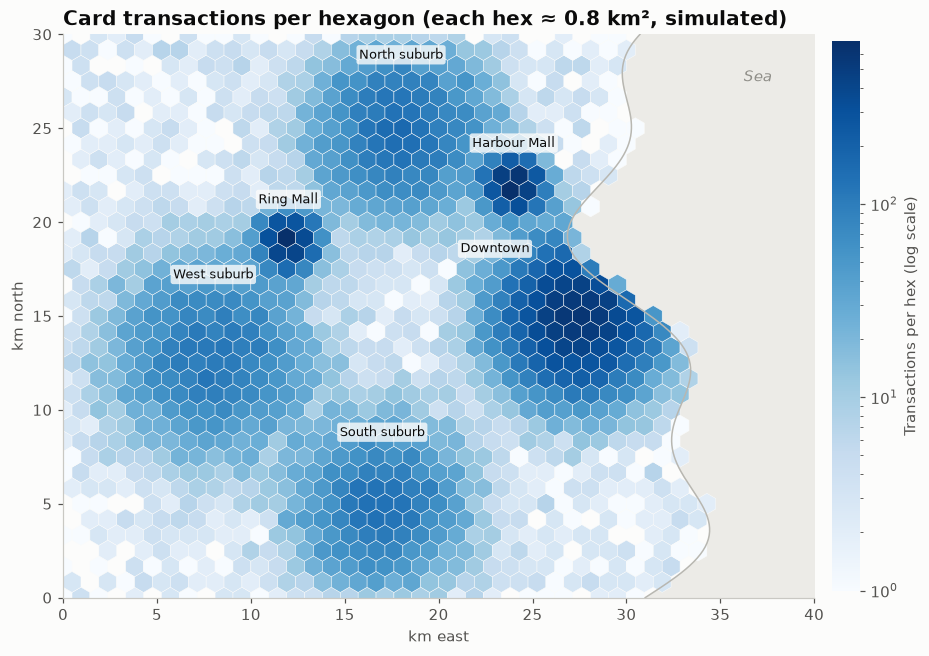

In [3]:
fig, ax = plt.subplots(figsize=(9, 6.6))
yy = np.linspace(0, 30, 300)
ax.fill_betweenx(yy, coast_x(yy), 40, color="#ecebe7", zorder=0)
ax.plot(coast_x(yy), yy, color="#b8b7b1", linewidth=1)
ax.text(37, 27.5, "Sea", color="#8f8e88", fontsize=10, style="italic", ha="center")
hb = ax.hexbin(df["x_km"], df["y_km"], gridsize=(42, 18), extent=(0, 40, 0, 30), mincnt=1,
               cmap=SEQ_CMAP, norm=LogNorm(), linewidths=0.3, edgecolors="#fcfcfb")
for name, (x, y, s, share) in centres.items():
    ax.annotate(name, (x, y), xytext=(x - 4.5 if name == "Downtown" else x, y + s + 1.2),
                ha="center", fontsize=8.5, color="#0b0b0b",
                bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec="none", alpha=0.8))
ax.set_xlim(0, 40)
ax.set_ylim(0, 30)
ax.set_aspect("equal")
ax.grid(False)
ax.set_xlabel("km east")
ax.set_ylabel("km north")
ax.set_title("Card transactions per hexagon (each hex ≈ 0.8 km², simulated)")
cb = fig.colorbar(hb, ax=ax, shrink=0.8, pad=0.02)
cb.set_label("Transactions per hex (log scale)")
cb.outline.set_visible(False)
fig.tight_layout()
plt.show()

## How to read it

The darkest hexes are downtown on the coast, with secondary hot spots at the suburban centres and the malls. Pale hexes along the edges show thin background activity, and the blank strip of sea on the right has none.

---
Standalone script: [`hexgrid_map.py`](hexgrid_map.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)